In [1]:
!pip install SpeechRecognition jiwer openai-whisper gTTS

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 9.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.9/32.9 MB 57.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 96.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.0/248.0 MB 5.2 MB/s eta 0:00:00
  Created wheel for openai-whisper: filename=openai_whisper-20250625-py3-none-any.whl size=803980 sha256=688dc453c072fa86057afda2442b4f416144b1f6b058ed6e3e9f6d6906718e83
  Stored in directory: /root/.cache/pip/wheels/ca/58/d5/fb4539ad74c3ca81eb40f7eda020ac77d080b33ad57449d485
Successfully built openai-whisper
  Attempting uninstall: click
    Found existing installation: click 8.5.0
    Uninstalling click-8.5.0:
      Successfully uninstalled click-8.5.0
ERROR: pip'

In [2]:
import numpy as np
import matplotlib.pyplot as plt


import librosa
import librosa.display
import soundfile as sf
import speech_recognition as sr
import whisper
import csv
import wave
import tempfile
from gtts import gTTS
from jiwer import wer, cer
from IPython.display import Audio

# Loading and Visualizing Audio File

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
#help(librosa.load)

In [5]:
audio_signal, sample_rate = librosa.load('/content/drive/MyDrive/Mastering_Gen_AI_&_LLM_Engg_4_July_2026-11_Oct_2026/08_Speech_Recognition/speech_01.wav', sr=None)

In [6]:
sample_rate/2

22050.0

In [7]:
audio_signal.shape

(1951232,)

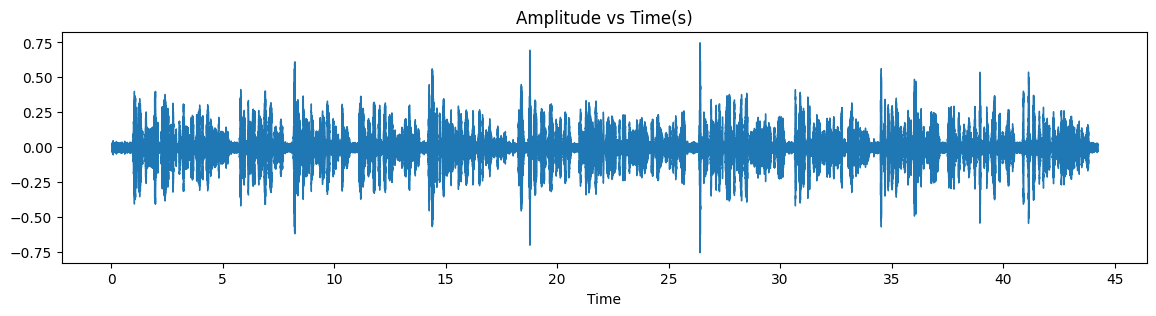

In [8]:
plt.figure(figsize=(14,3))
librosa.display.waveshow(audio_signal,sr=sample_rate)
plt.title('Amplitude vs Time(s)')
plt.show()

In [9]:
Audio('/content/drive/MyDrive/Mastering_Gen_AI_&_LLM_Engg_4_July_2026-11_Oct_2026/08_Speech_Recognition/speech_01.wav')

Output hidden; open in https://colab.research.google.com to view.

# Transcribe Audio with Google Web Service API

In [10]:
recognizer = sr.Recognizer()

In [11]:
file_path = '/content/drive/MyDrive/Mastering_Gen_AI_&_LLM_Engg_4_July_2026-11_Oct_2026/08_Speech_Recognition/speech_01.wav'

In [12]:
def transribe_audio(file_path):
  with sr.AudioFile(file_path) as source:
    audio_data = recognizer.record(source)
    text = recognizer.recognize_google(audio_data)
    print(text)
    return text

In [13]:
transcribed_text = transribe_audio(file_path=file_path)

my name is shreyas and I'm excited to have you as part of my learning community I'd like to share a little about myself I'm an analytical engineer by qualification holding an aircraft maintenance engineer license and I later transition into the world of artificial intelligence today I work as an AI facilitator and freelance trainer with a strong focus on machine learning deep learning and generative AI I'll bring a systems oriented real world engineering mindset to AI combining python best implementation with clear explanation my professional Journey Bridges engineering analytical thinking and practical AI problem solving with a deep emphasis on Industrial relevant skills


In [14]:
ground_truth = """My name is Shreyas, and I’m excited to have you as part of my learning community! I’d like to
share a little about myself. I’m an aeronautical engineer by qualification,
holding an Aircraft Maintenance Engineer license, and I later transitioned into the world of Artificial
Intelligence. Today, I work as an AI facilitator and freelance trainer with a strong focus on Machine Learning,
Deep Learning, and Generative AI. I bring a systems-oriented, real-world engineering mindset to AI,
combining Python-based implementation with clear, intuitive explanations. My professional journey bridges
high-stakes engineering, analytical thinking, and practical AI problem-solving, with a deep emphasis on industry-relevant skills."""

* WER : what %age of words the system got wrong in a transcription. Counts 3 types of mistakes : Substituion, Insertion , deletion
* CER : operates at character level

In [15]:
calculated_wer = wer(ground_truth.lower(), transcribed_text.lower())
calculated_cer = cer(ground_truth.lower(), transcribed_text.lower())


print(f"WER : {calculated_wer}")
print(f"CER : {calculated_cer}")

WER : 0.41237113402061853
CER : 0.0970873786407767


In [16]:
len(ground_truth)

721

In [17]:
.12*721

86.52

##  Background Noise and Spectrograms

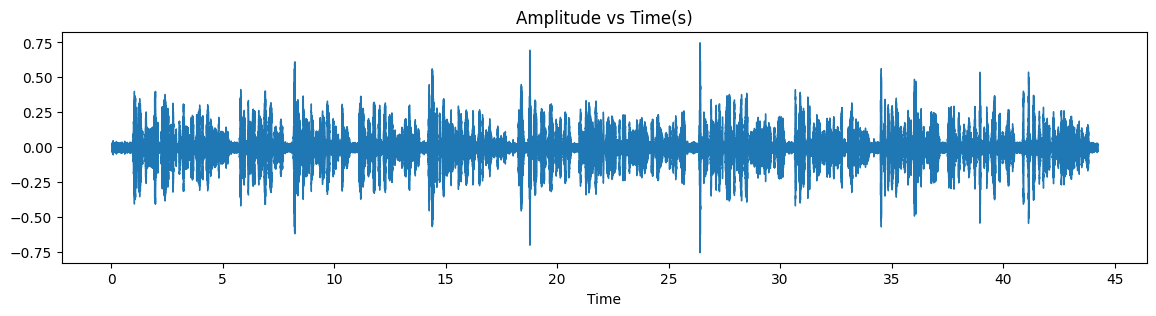

In [18]:
plt.figure(figsize=(14,3))
librosa.display.waveshow(audio_signal,sr=sample_rate)
plt.title('Amplitude vs Time(s)')
plt.show()

In [19]:
S = librosa.stft(audio_signal)

In [20]:
S_dB = librosa.amplitude_to_db(abs(S), ref=np.max)

In [21]:
np.max(S_dB)

np.float32(0.0)

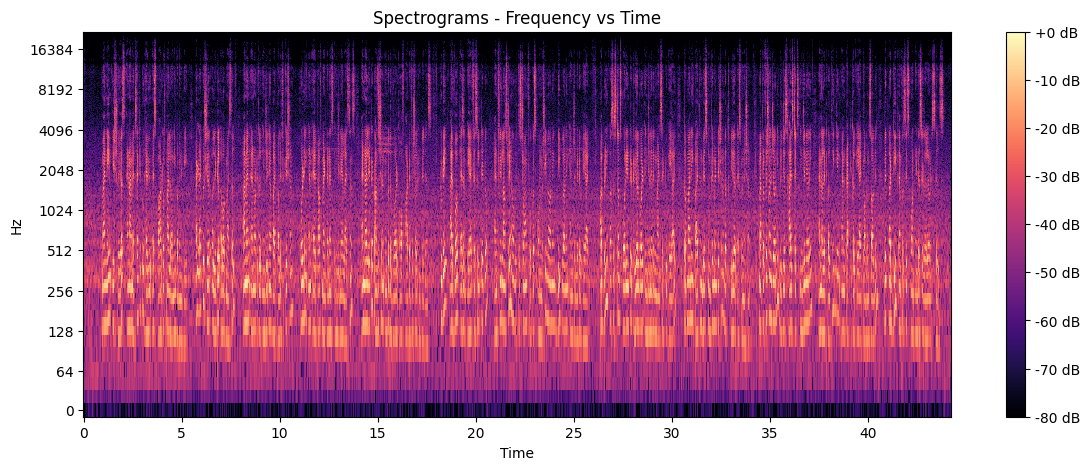

In [22]:
plt.figure(figsize=(14,5))
librosa.display.specshow(data=S_dB, sr = sample_rate,x_axis='time',y_axis='log')
plt.colorbar(format="%+2.0f dB")
plt.title('Spectrograms - Frequency vs Time')
plt.show()

In [23]:
signal_filtered = librosa.effects.preemphasis(audio_signal,coef=0.97)
sf.write('/content/drive/MyDrive/Mastering_Gen_AI_&_LLM_Engg_4_July_2026-11_Oct_2026/08_Speech_Recognition/filtered_speech_01.wav',signal_filtered,sample_rate)


In [24]:
output_file = '/content/drive/MyDrive/Mastering_Gen_AI_&_LLM_Engg_4_July_2026-11_Oct_2026/08_Speech_Recognition/filtered_speech_01.wav'

In [25]:
print(f'Playing the original audio:\n')
Audio(file_path)


Output hidden; open in https://colab.research.google.com to view.

In [26]:
print(f'Playing the Filtered audio:\n')
Audio(output_file)

Output hidden; open in https://colab.research.google.com to view.

In [27]:
Sb = librosa.stft(signal_filtered)

In [28]:
S_dBb = librosa.amplitude_to_db(abs(Sb), ref=np.max)

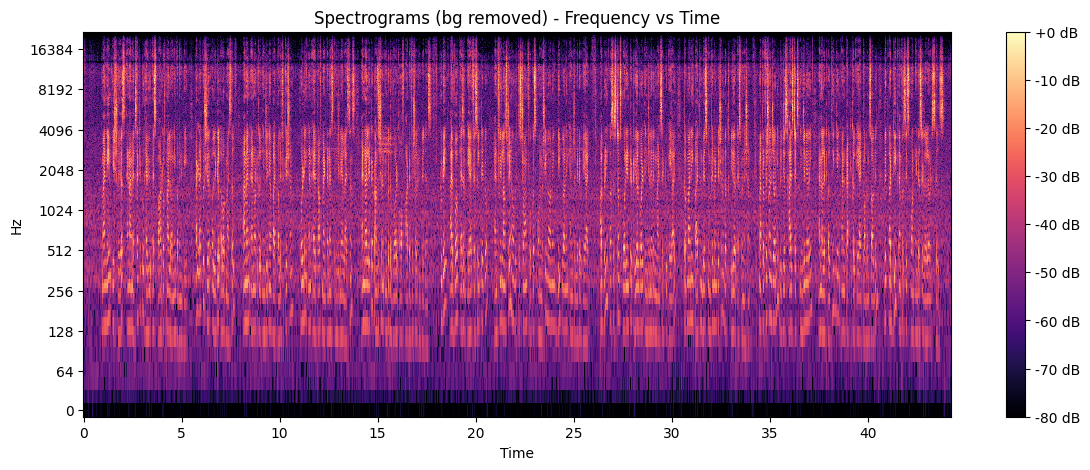

In [29]:
plt.figure(figsize=(14,5))
librosa.display.specshow(data=S_dBb, sr = sample_rate,x_axis='time',y_axis='log')
plt.colorbar(format="%+2.0f dB")
plt.title('Spectrograms (bg removed) - Frequency vs Time')
plt.show()

In [30]:
transcribe_preemphasis = transribe_audio(output_file)

my name is shreyas and I'm excited to have you as part of my learning community I'd like to share a little about myself I'm an analytical engineer by qualification holding an aircraft maintenance engineer license and I later transition into the world of artificial intelligence today I work as an AI facilitator and freelance trainer with a strong focus on machine learning deep learning and generative AI I'll bring a systems oriented real world engineering mindset to AI good morning best implementation with clear explanation my professional Journey Bridges engineering analytical thinking and practical AI problem solving with a deep emphasis on Industrial relevant skills


In [31]:
calculated_wer = wer(ground_truth.lower(), transcribe_preemphasis.lower())
calculated_cer = cer(ground_truth.lower(), transcribe_preemphasis.lower())


print(f"WER : {calculated_wer}")
print(f"CER : {calculated_cer}")

WER : 0.41237113402061853
CER : 0.11234396671289876


# Transcribing Adio with Whisper

In [42]:
model = whisper.load_model('base') #small, medium, large

In [43]:
result = model.transcribe(file_path)

/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


In [44]:
transcribed_text_whisper = result['text']

In [45]:
result['language']

'en'

In [46]:
calculated_wer = wer(ground_truth.lower(), transcribed_text_whisper.lower())
calculated_cer = cer(ground_truth.lower(), transcribed_text_whisper.lower())


print(f"WER : {calculated_wer}")
print(f"CER : {calculated_cer}")

WER : 0.41237113402061853
CER : 0.07489597780859916


In [47]:
calculated_wer = wer(ground_truth, transcribed_text_whisper)
calculated_cer = cer(ground_truth, transcribed_text_whisper)


print(f"WER : {calculated_wer}")
print(f"CER : {calculated_cer}")

WER : 0.4639175257731959
CER : 0.08876560332871013


Transcribing Multiple Audio Files

In [48]:
directory_path = '/content/drive/MyDrive/Mastering_Gen_AI_&_LLM_Engg_4_July_2026-11_Oct_2026/08_Speech_Recognition/Sample wav'

In [49]:
import os

In [52]:
def transcribe_directory_whisper(path):
  transcriptions = []
  for file_name in os.listdir(directory_path):
    if file_name.endswith('.wav'):
      files_path = os.path.join(path,file_name)
      result = model.transcribe(files_path)

      transcription = result['text']
      transcriptions.append({
          'file_name':file_name,
          'transcription' : transcription
      })
  return transcriptions

In [56]:
transcriptions = transcribe_directory_whisper(path=directory_path)
transcriptions

/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")
/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


[{'file_name': 'harvard.wav',
  'transcription': ' The stale smell of old beer lingers. It takes heat to bring out the odor. A cold dip restores health and zest. A salt pickle tastes fine with ham. Tacos al pastor are my favorite. A zestful food is the hot cross bun.'},
 {'file_name': 'jackhammer.wav',
  'transcription': ' The still smell of cold beer lingers.'}]

# Saving the Transcriptions in CSV file

In [58]:
output_file = '/content/drive/MyDrive/Mastering_Gen_AI_&_LLM_Engg_4_July_2026-11_Oct_2026/08_Speech_Recognition/transcriptions.csv'

with open(output_file,'w',newline='') as file:
  writer = csv.writer(file)
  writer.writerow(['Track Number','File Name','Transcription'])
  for number, transcription in enumerate(transcriptions, start=1):
    writer.writerow([number, transcription['file_name'],transcription['transcription']])


# Text - to -Speech

In [60]:
text = '''
Thank you for attending this course on Generative AI. We are left with 2 more sessions after this.
Next week, both the sessions would be on saturday. After that, It would be "See You Soon" !
'''


tts = gTTS(text=text,lang='en')

tts.save('/content/drive/MyDrive/Mastering_Gen_AI_&_LLM_Engg_4_July_2026-11_Oct_2026/08_Speech_Recognition/output.mp3')